# Logistics Delivery Performance Analysis
## Yuva Intern – Technical Project

**Objective:** Analyse shipment performance, calculate operational KPIs, explore delay patterns, and build a baseline delivery-time prediction model.

> **Dataset notice:** The included CSV is a reproducible **synthetic demonstration dataset** generated for this portfolio project. It is not company data and must not be presented as real operational evidence. Replace it with an authorized real dataset if one is provided.

### Project workflow
1. Load and inspect shipment data
2. Clean and validate data
3. Calculate logistics KPIs
4. Explore delivery performance by region, carrier, service, and distance
5. Visualize key patterns
6. Build and evaluate a baseline regression model
7. Summarize limitations and recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# In Google Colab, upload the CSV when prompted, or use the included project data path.
try:
    DATA_PATH = Path("/content/logistics_shipments_synthetic.csv")
    if not DATA_PATH.exists():
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = Path(next(iter(uploaded)))
except Exception:
    DATA_PATH = Path("data/logistics_shipments_synthetic.csv")

df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
display(df.head())
df.info()

Saving logistics_shipments_synthetic.csv to logistics_shipments_synthetic.csv
Rows, columns: (600, 14)


,order_id,shipment_id,order_date,warehouse,region,carrier,service_type,planned_distance_km,shipment_weight_kg,dispatch_time,promised_delivery_time,delivered_time,status,actual_cost_inr
0,ORD-0001,SHP-0001,2026-07-09,WH-02,South,Carrier A,Standard,82.2,4.6,2026-07-09 13:00:00,2026-07-09 20:05:03.554777072,2026-07-09 19:09:37.004153976,Delivered,168.92
1,ORD-0002,SHP-0002,2026-09-08,WH-03,Central,Carrier B,Standard,84.9,4.5,2026-09-08 13:00:00,2026-09-08 17:55:31.271235697,2026-09-08 17:55:31.271235697,Delivered,201.68
2,ORD-0003,SHP-0003,2026-08-28,WH-03,North,Carrier A,Standard,257.7,7.9,2026-08-28 03:00:00,2026-08-28 14:50:35.394986536,2026-08-28 11:46:21.774064101,Delivered,499.66
3,ORD-0004,SHP-0004,2026-08-09,WH-01,South,Carrier B,Express,85.9,17.0,2026-08-09 06:00:00,2026-08-09 08:00:42.476708804,2026-08-09 08:00:42.476708804,Delivered,269.27
4,ORD-0005,SHP-0005,2026-08-08,WH-03,North,Carrier B,Standard,126.6,19.2,2026-08-08 09:00:00,2026-08-08 17:06:25.787992852,2026-08-08 17:06:25.787992852,Delivered,315.39


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_id                600 non-null    object 
 1   shipment_id             600 non-null    object 
 2   order_date              600 non-null    object 
 3   warehouse               600 non-null    object 
 4   region                  600 non-null    object 
 5   carrier                 595 non-null    object 
 6   service_type            600 non-null    object 
 7   planned_distance_km     600 non-null    float64
 8   shipment_weight_kg      592 non-null    float64
 9   dispatch_time           600 non-null    object 
 10  promised_delivery_time  600 non-null    object 
 11  delivered_time          541 non-null    object 
 12  status                  600 non-null    object 
 13  actual_cost_inr         600 non-null    float64
dtypes: float64(3), object(11)
memory usage: 65

## 1. Data quality checks
Check missing values, duplicate shipment IDs, and timestamp consistency before calculating metrics.

In [2]:
# Parse timestamps
date_cols = ["order_date", "dispatch_time", "promised_delivery_time", "delivered_time"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print("Missing values by column:")
display(df.isna().sum().to_frame("missing_count"))
print("Duplicate shipment IDs:", df["shipment_id"].duplicated().sum())

# Basic validation flags
df["negative_distance_flag"] = df["planned_distance_km"] < 0
df["negative_cost_flag"] = df["actual_cost_inr"] < 0
df["invalid_time_order_flag"] = (
    df["delivered_time"].notna()
    & df["dispatch_time"].notna()
    & (df["delivered_time"] < df["dispatch_time"])
)
print("Negative distance rows:", int(df["negative_distance_flag"].sum()))
print("Negative cost rows:", int(df["negative_cost_flag"].sum()))
print("Invalid delivery chronology rows:", int(df["invalid_time_order_flag"].sum()))

Missing values by column:


,missing_count
order_id,0
shipment_id,0
order_date,0
warehouse,0
region,0
carrier,5
service_type,0
planned_distance_km,0
shipment_weight_kg,8
dispatch_time,0


Duplicate shipment IDs: 0
Negative distance rows: 0
Negative cost rows: 0
Invalid delivery chronology rows: 0


## 2. Prepare analysis dataset
For this demonstration, completed deliveries with valid dispatch and delivery timestamps are used for delivery-time and on-time calculations. Missing weights are filled with the median for modelling only.

In [3]:
completed = df[
    df["status"].eq("Delivered")
    & df["dispatch_time"].notna()
    & df["delivered_time"].notna()
].copy()

completed["delivery_hours"] = (
    completed["delivered_time"] - completed["dispatch_time"]
).dt.total_seconds() / 3600

completed["on_time"] = (
    completed["promised_delivery_time"].notna()
    & (completed["delivered_time"] <= completed["promised_delivery_time"])
)

completed["shipment_weight_kg"] = completed["shipment_weight_kg"].fillna(
    completed["shipment_weight_kg"].median()
)
print("Completed shipments:", len(completed))
display(completed[["shipment_id", "delivery_hours", "on_time"]].head())

Completed shipments: 541


,shipment_id,delivery_hours,on_time
0,SHP-0001,6.160279,True
1,SHP-0002,4.925353,True
2,SHP-0003,8.772715,True
3,SHP-0004,2.011799,True
4,SHP-0005,8.107163,True


## 3. Calculate core logistics KPIs
Definitions used here: on-time rate is on-time completed deliveries divided by completed deliveries with a valid promise time; cost per delivered shipment is total cost for completed shipments divided by completed shipments; average delivery time is dispatch-to-delivery duration.

In [4]:
eligible_ontime = completed[completed["promised_delivery_time"].notna()]
on_time_rate = eligible_ontime["on_time"].mean() * 100 if len(eligible_ontime) else np.nan
avg_delivery_hours = completed["delivery_hours"].mean()
cost_per_delivery = completed["actual_cost_inr"].sum() / len(completed) if len(completed) else np.nan
failed_rate = (df["status"].eq("Failed Attempt").mean() * 100)

kpis = pd.DataFrame({
    "KPI": ["On-time delivery rate", "Average delivery time", "Cost per completed delivery", "Failed-attempt shipment share"],
    "Value": [on_time_rate, avg_delivery_hours, cost_per_delivery, failed_rate],
    "Unit": ["%", "hours", "INR / delivery", "% of all shipments"]
})
display(kpis.round(2))

,KPI,Value,Unit
0,On-time delivery rate,90.20,%
1,Average delivery time,4.84,hours
2,Cost per completed delivery,275.17,INR / delivery
3,Failed-attempt shipment share,6.17,% of all shipments


## 4. Performance by region and carrier

In [5]:
region_summary = completed.groupby("region").agg(
    shipments=("shipment_id", "count"),
    avg_delivery_hours=("delivery_hours", "mean"),
    on_time_rate=("on_time", "mean"),
    avg_cost_inr=("actual_cost_inr", "mean")
).reset_index()
region_summary["on_time_rate"] *= 100
display(region_summary.round(2).sort_values("on_time_rate"))

carrier_summary = completed.groupby("carrier").agg(
    shipments=("shipment_id", "count"),
    avg_delivery_hours=("delivery_hours", "mean"),
    on_time_rate=("on_time", "mean"),
    avg_cost_inr=("actual_cost_inr", "mean")
).reset_index()
carrier_summary["on_time_rate"] *= 100
display(carrier_summary.round(2))

,region,shipments,avg_delivery_hours,on_time_rate,avg_cost_inr
1,East,117,4.73,87.18,275.25
2,North,90,4.95,90.00,271.34
3,South,120,4.97,90.00,277.90
4,West,100,4.75,91.00,272.96
0,Central,114,4.80,92.98,277.18


,carrier,shipments,avg_delivery_hours,on_time_rate,avg_cost_inr
0,Carrier A,208,4.56,92.31,280.26
1,Carrier B,198,5.06,88.38,272.00
2,Carrier C,130,4.93,90.77,270.05


## 5. Visualize delivery performance

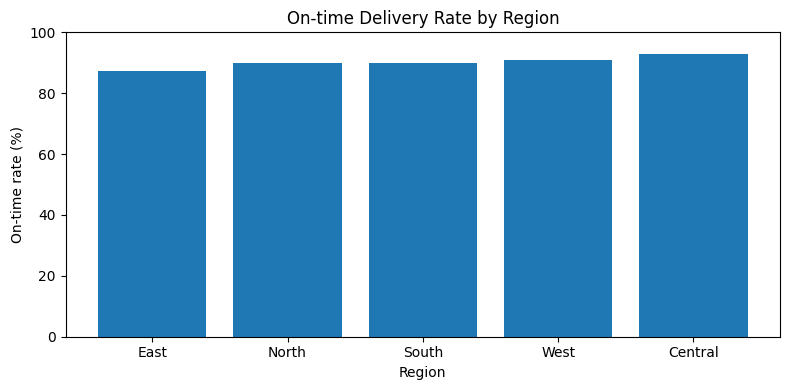

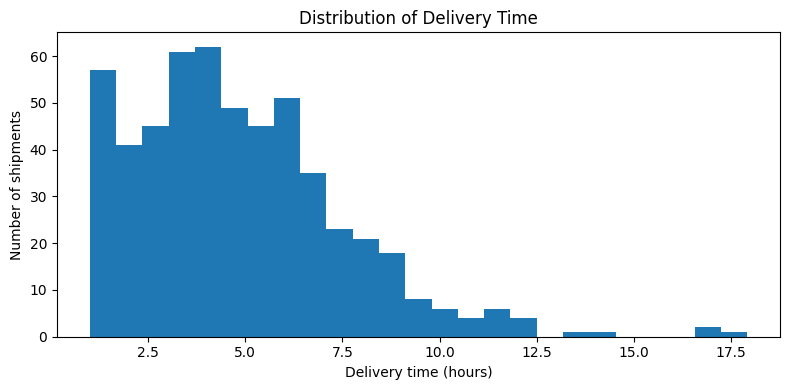

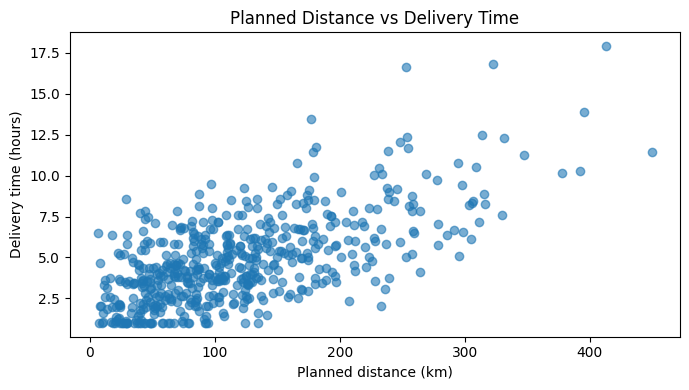

In [6]:
# On-time delivery rate by region
region_plot = region_summary.sort_values("on_time_rate")
plt.figure(figsize=(8, 4))
plt.bar(region_plot["region"], region_plot["on_time_rate"])
plt.title("On-time Delivery Rate by Region")
plt.xlabel("Region")
plt.ylabel("On-time rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Delivery-time distribution
plt.figure(figsize=(8, 4))
plt.hist(completed["delivery_hours"], bins=25)
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery time (hours)")
plt.ylabel("Number of shipments")
plt.tight_layout()
plt.show()

# Planned distance vs delivery duration
plt.figure(figsize=(7, 4))
plt.scatter(completed["planned_distance_km"], completed["delivery_hours"], alpha=0.6)
plt.title("Planned Distance vs Delivery Time")
plt.xlabel("Planned distance (km)")
plt.ylabel("Delivery time (hours)")
plt.tight_layout()
plt.show()

## 6. Baseline delivery-time regression
A simple model is used to demonstrate the modelling workflow. A random train/test split is shown for an introductory exercise; for a production forecasting system, use a chronological split and ensure all features are known at prediction time.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

model_data = completed.dropna(subset=["delivery_hours"]).copy()
features = ["planned_distance_km", "shipment_weight_kg", "service_type", "region", "carrier"]
target = "delivery_hours"
X = model_data[features]
y = model_data[target]

numeric_features = ["planned_distance_km", "shipment_weight_kg"]
categorical_features = ["service_type", "region", "carrier"]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

regression_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
regression_model.fit(X_train, y_train)
predictions = regression_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
print(f"Mean Absolute Error (hours): {mae:.2f}")
print(f"Root Mean Squared Error (hours): {rmse:.2f}")

Mean Absolute Error (hours): 1.53
Root Mean Squared Error (hours): 1.90


## 7. Findings and business recommendations

Use the tables and charts generated above to identify which regions or carriers have relatively lower on-time performance, longer delivery duration, or higher average cost. Do not assume a difference is caused by the carrier or region alone; distance, service mix, shipment weight, and sample size may differ.

### Recommended actions to validate
- Investigate regions with lower on-time rates and review dispatch cut-offs, route conditions, and delivery windows.
- Compare carriers on similar service types and distance bands before making allocation decisions.
- Review high-cost shipment groups and test consolidation only where customer commitments can still be met.
- Use delivery-time predictions as planning support only after time-based validation and operational review.

## 8. Limitations
- The dataset is synthetic and does not represent a real logistics company.
- Results are illustrative and cannot support claims about actual industry performance.
- The baseline model is educational; it needs time-based validation and more operational features before deployment.
- Route optimization is not implemented because a reliable road-network travel-time matrix, vehicle constraints, and delivery time windows are not included.

## Conclusion
This project demonstrates an end-to-end logistics analytics workflow: data inspection, cleaning, KPI calculation, exploratory analysis, visualization, and baseline regression. The next step for a real organization would be to repeat the workflow on authorized operational data, validate findings with logistics stakeholders, and test improvement ideas through a controlled pilot.